In [249]:
import pandas as pd
from IPython.core.pylabtools import figsize
import numpy as np

data = pd.read_csv('train.csv')
data['datetime'] = pd.to_datetime(data['datetime'])

data['year'] = data['datetime'].dt.year
data['month'] = data['datetime'].dt.month
data["dayofweek"] = data["datetime"].dt.dayofweek
data['day'] = data['datetime'].dt.day
data['hour'] = data['datetime'].dt.hour

test_data = pd.read_csv("test.csv")
raw_test = test_data.copy()
test_data["datetime"] = pd.to_datetime(test_data["datetime"])

test_data["year"] = test_data["datetime"].dt.year
test_data["month"] = test_data["datetime"].dt.month
test_data["dayofweek"] = test_data["datetime"].dt.dayofweek
test_data["day"] = test_data["datetime"].dt.day
test_data["hour"] = test_data["datetime"].dt.hour

test_data = test_data.drop(columns=['datetime'])

cutoff = int(len(data) * 0.8)
train = data[:cutoff]
valid = data[cutoff:]

train_target = train['count']
valid_target = valid['count']
all_target = pd.concat([train_target, valid_target])

train = train.drop(columns=['count', 'datetime', 'casual', 'registered'])
valid = valid.drop(columns=['count', 'datetime', 'casual', 'registered'])
all = pd.concat([train, valid])

In [250]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[ns]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
 12  year        10886 non-null  int32         
 13  month       10886 non-null  int32         
 14  dayofweek   10886 non-null  int32         
 15  day         10886 non-null  int32         
 16  hour        10886 non-

In [251]:
data.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,dayofweek,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,5,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,5,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,5,1,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011,1,5,1,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011,1,5,1,4


array([[<Axes: title={'center': 'datetime'}>,
        <Axes: title={'center': 'season'}>,
        <Axes: title={'center': 'holiday'}>,
        <Axes: title={'center': 'workingday'}>],
       [<Axes: title={'center': 'weather'}>,
        <Axes: title={'center': 'temp'}>,
        <Axes: title={'center': 'atemp'}>,
        <Axes: title={'center': 'humidity'}>],
       [<Axes: title={'center': 'windspeed'}>,
        <Axes: title={'center': 'casual'}>,
        <Axes: title={'center': 'registered'}>,
        <Axes: title={'center': 'count'}>],
       [<Axes: title={'center': 'year'}>,
        <Axes: title={'center': 'month'}>,
        <Axes: title={'center': 'dayofweek'}>,
        <Axes: title={'center': 'day'}>],
       [<Axes: title={'center': 'hour'}>, <Axes: >, <Axes: >, <Axes: >]],
      dtype=object)

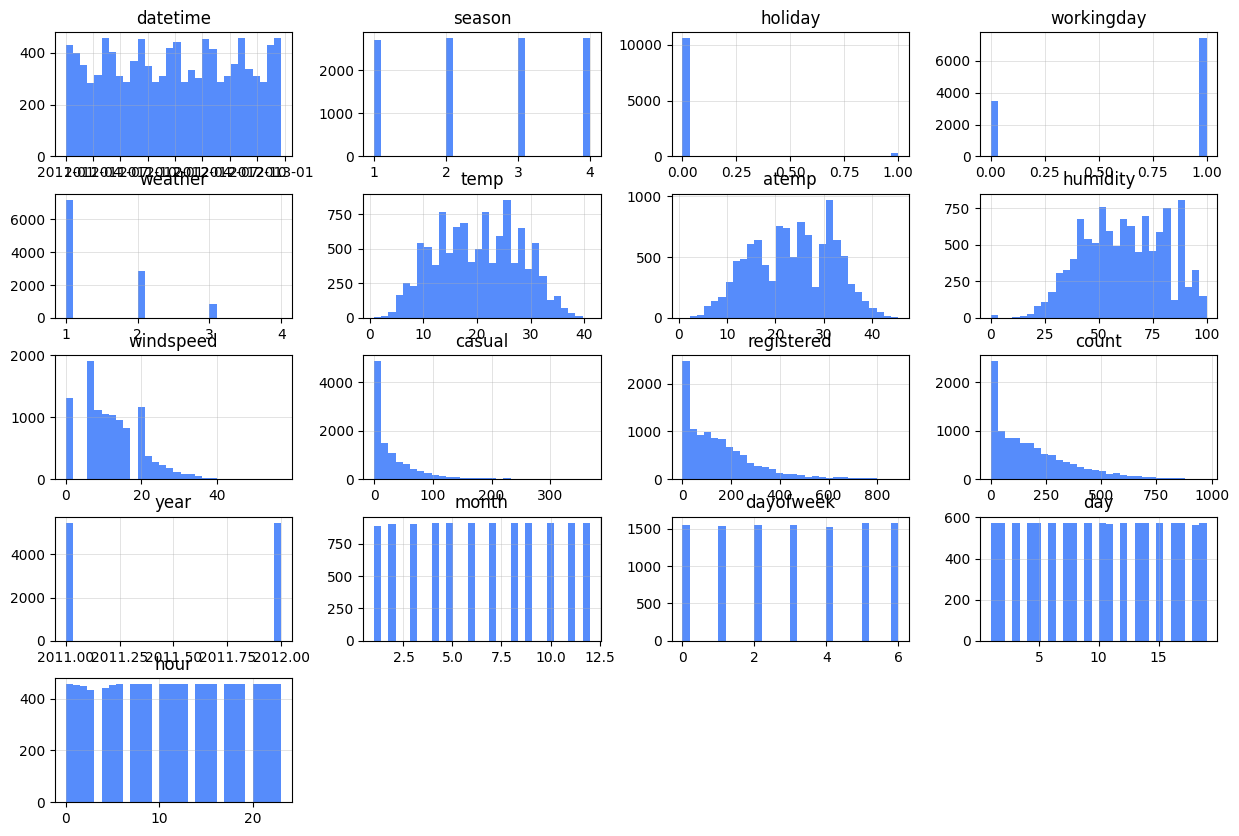

In [252]:
data.hist(figsize=(15,10), bins=30)

<Axes: >

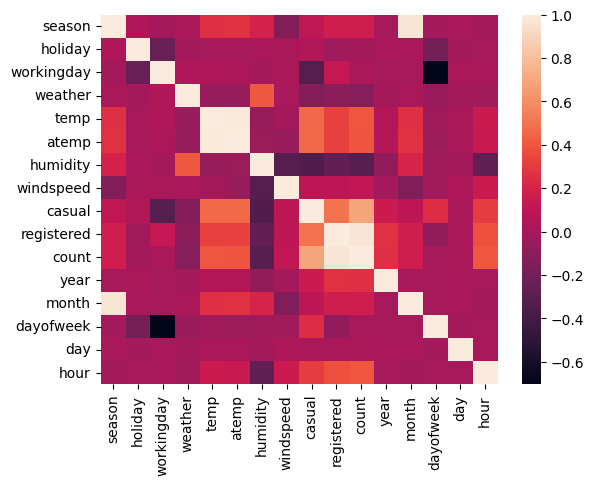

In [253]:
import seaborn as sns

sns.heatmap(data.drop(columns='datetime').corr())

In [254]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=500,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42,
)

hgbr.fit(train, train_target)
pred = hgbr.predict(valid)
pred = pred.clip(min=0)

In [255]:
from sklearn.metrics import root_mean_squared_log_error

rmsle = root_mean_squared_log_error(valid_target, pred)
rmsle

0.4020308866963118

In [256]:
final_hgbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=500,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42,
)

final_hgbr.fit(all, all_target)

test_pred = final_hgbr.predict(test_data)

submission = pd.DataFrame({
    'datetime': raw_test['datetime'],
    'count': test_pred,
})

submission.to_csv('submission.csv', index=False)